# Практика 1.3. Дерево решений

**Задача:** предсказать, сдаст ли студент итоговый экзамен по португальскому языку (оценка G3 ≥ 10 из 20), по социальным, семейным и учебным характеристикам.

**Датасет:** [Student Performance (UCI)](https://archive.ics.uci.edu/dataset/320/student+performance) — 649 студентов двух португальских школ, 30 признаков (файл `student-por.csv`). Многие признаки — **текстовые категории** (`yes`/`no`, профессия родителей и т. д.), что требует кодирования.

Ключевые признаки: `studytime` — время на учёбу (1–4), `failures` — число прошлых неудач, `higher` — хочет ли получать высшее образование, `absences` — пропуски занятий, `Medu`/`Fedu` — образование матери/отца (0–4), `Dalc`/`Walc` — употребление алкоголя в будни/выходные (1–5).

## 0. Зависимости и импорты

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlflow

In [2]:
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

## 1. Настройки и вспомогательные функции

In [3]:
EXPERIMENT_NAME = "p1_decision_tree"
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"
TARGET = "passed"
PASS_THRESHOLD = 10
GRADE_COLS = ["G1", "G2", "G3"]
ORDINAL_RANGES = {
    "Medu": (0, 4), "Fedu": (0, 4), "traveltime": (1, 4), "studytime": (1, 4),
    "failures": (0, 4), "famrel": (1, 5), "freetime": (1, 5), "goout": (1, 5),
    "Dalc": (1, 5), "Walc": (1, 5), "health": (1, 5), "age": (15, 22),
    "absences": (0, 93), "G1": (0, 20), "G2": (0, 20), "G3": (0, 20),
}
PARAM_GRID = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "criterion": ["gini", "entropy"],
}


SEED = 42
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
MLFLOW_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT_NAME)


def download(url, filename):
    path = DATA_DIR / filename
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def quality_report(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_%": (frame.isna().mean() * 100).round(2),
        "unique": frame.nunique(),
    })


def iqr_outlier_mask(frame, k=1.5):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return (frame < q1 - k * iqr) | (frame > q3 + k * iqr)


def classification_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }

2026/11/11 14:40:55 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/11 14:40:55 INFO mlflow.store.db.utils: Updating database tables
2026/11/11 14:41:03 INFO mlflow.tracking.fluent: Experiment with name 'p1_decision_tree' does not exist. Creating a new experiment.


**Трекинг экспериментов.** Все запуски логируются в MLflow (база `mlflow.db` в корне репозитория).
Посмотреть результаты: из корня репозитория выполнить `mlflow ui --backend-store-uri sqlite:///mlflow.db` и открыть http://127.0.0.1:5000.

## 2. Загрузка данных
В архиве два набора (математика и португальский); берём португальский — он больше. Разделитель — `;`.

In [4]:
with zipfile.ZipFile(download(DATA_URL, "student.zip")) as archive:
    with archive.open("student-por.csv") as f:
        raw = pd.read_csv(f, sep=";")
df = raw.copy()
print(f"Размер: {df.shape}")
df.head()

Размер: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

## 3. Качество данных
### 3.1. Пропуски и типы

In [6]:
quality_report(df).T

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
dtype,object,object,int64,object,object,object,int64,int64,object,object,object,object,int64,int64,int64,object,object,object,object,object,object,object,object,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
missing_%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
unique,2,2,8,2,2,2,5,5,5,5,4,3,4,4,4,2,2,2,2,2,2,2,2,5,5,5,5,5,5,24,17,16,17


Стратегия для пропусков (если появятся в другой версии файла): строки без оценки G3 удаляются, пропуски в признаках заполняются модой внутри Pipeline (`SimpleImputer`).

In [7]:
df = df.dropna(subset=["G3"]).reset_index(drop=True)
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = [c for c in df.select_dtypes(include="number").columns if c not in GRADE_COLS]
for col in cat_cols:
    df[col] = df[col].str.strip()
print(f"Категориальных признаков: {len(cat_cols)}, числовых: {len(num_cols)}")
for col in cat_cols:
    print(f"{col:>11}: {sorted(df[col].dropna().unique())}")

Категориальных признаков: 17, числовых: 13
     school: ['GP', 'MS']
        sex: ['F', 'M']
    address: ['R', 'U']
    famsize: ['GT3', 'LE3']
    Pstatus: ['A', 'T']
       Mjob: ['at_home', 'health', 'other', 'services', 'teacher']
       Fjob: ['at_home', 'health', 'other', 'services', 'teacher']
     reason: ['course', 'home', 'other', 'reputation']
   guardian: ['father', 'mother', 'other']
  schoolsup: ['no', 'yes']
     famsup: ['no', 'yes']
       paid: ['no', 'yes']
 activities: ['no', 'yes']
    nursery: ['no', 'yes']
     higher: ['no', 'yes']
   internet: ['no', 'yes']
   romantic: ['no', 'yes']


### 3.2. «Битые» значения
Многие числовые признаки — порядковые шкалы с известным диапазоном (например, `famrel` от 1 до 5). Значения вне шкалы — ошибки ввода.

In [8]:
out_of_range = pd.Series({
    col: int((~df[col].between(low, high)).sum())
    for col, (low, high) in ORDINAL_RANGES.items()
}, name="вне допустимого диапазона")
print(out_of_range.to_string())
broken = pd.concat([~df[col].between(low, high) for col, (low, high) in ORDINAL_RANGES.items()], axis=1).any(axis=1)
df = df.loc[~broken].reset_index(drop=True)
print(f"Удалено строк с битыми значениями: {broken.sum()}")

Medu          0
Fedu          0
traveltime    0
studytime     0
failures      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
age           0
absences      0
G1            0
G2            0
G3            0
Удалено строк с битыми значениями: 0


### 3.3. Дубликаты

In [9]:
n_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {n_duplicates}")
df = df.drop_duplicates().reset_index(drop=True)

Полных дубликатов: 0


### 3.4. Аномалии
- **Нулевая итоговая оценка G3 = 0** при ненулевых промежуточных — скорее всего, студент не пришёл на экзамен (отчислен). Это не ошибка, а реальный исход «не сдал», поэтому оставляем.
- **Пропуски занятий (`absences`)** — длинный хвост. Дерево решений нечувствительно к масштабу и выбросам (оно лишь выбирает порог разбиения), поэтому выбросы не удаляем.

Студентов с G3 = 0: 15; из них с G2 > 0: 8
Выбросов по IQR в absences: 21


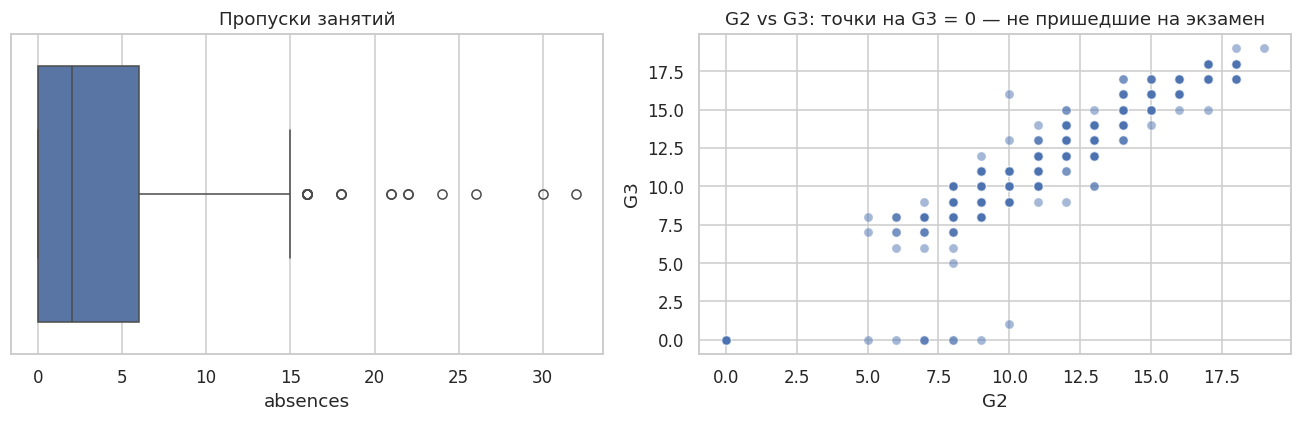

In [10]:
zero_g3 = df[df["G3"] == 0]
print(f"Студентов с G3 = 0: {len(zero_g3)}; из них с G2 > 0: {(zero_g3['G2'] > 0).sum()}")
print(f"Выбросов по IQR в absences: {iqr_outlier_mask(df[['absences']]).sum().iloc[0]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["absences"], ax=axes[0])
axes[0].set_title("Пропуски занятий")
sns.scatterplot(data=df, x="G2", y="G3", alpha=0.5, ax=axes[1])
axes[1].set_title("G2 vs G3: точки на G3 = 0 — не пришедшие на экзамен")
plt.tight_layout()
plt.show()

### 3.5. Целевая переменная
Бинаризуем итоговую оценку: G3 ≥ 10 — «сдал» (1), иначе — «не сдал» (0). Это стандартный порог в португальской 20-балльной системе.

In [11]:
df[TARGET] = (df["G3"] >= PASS_THRESHOLD).astype(int)
print(df[TARGET].value_counts(normalize=True).round(3))

passed
1    0.846
0    0.154
Name: proportion, dtype: float64


## 4. Разведочный анализ (EDA)
### 4.1. Распределения числовых признаков

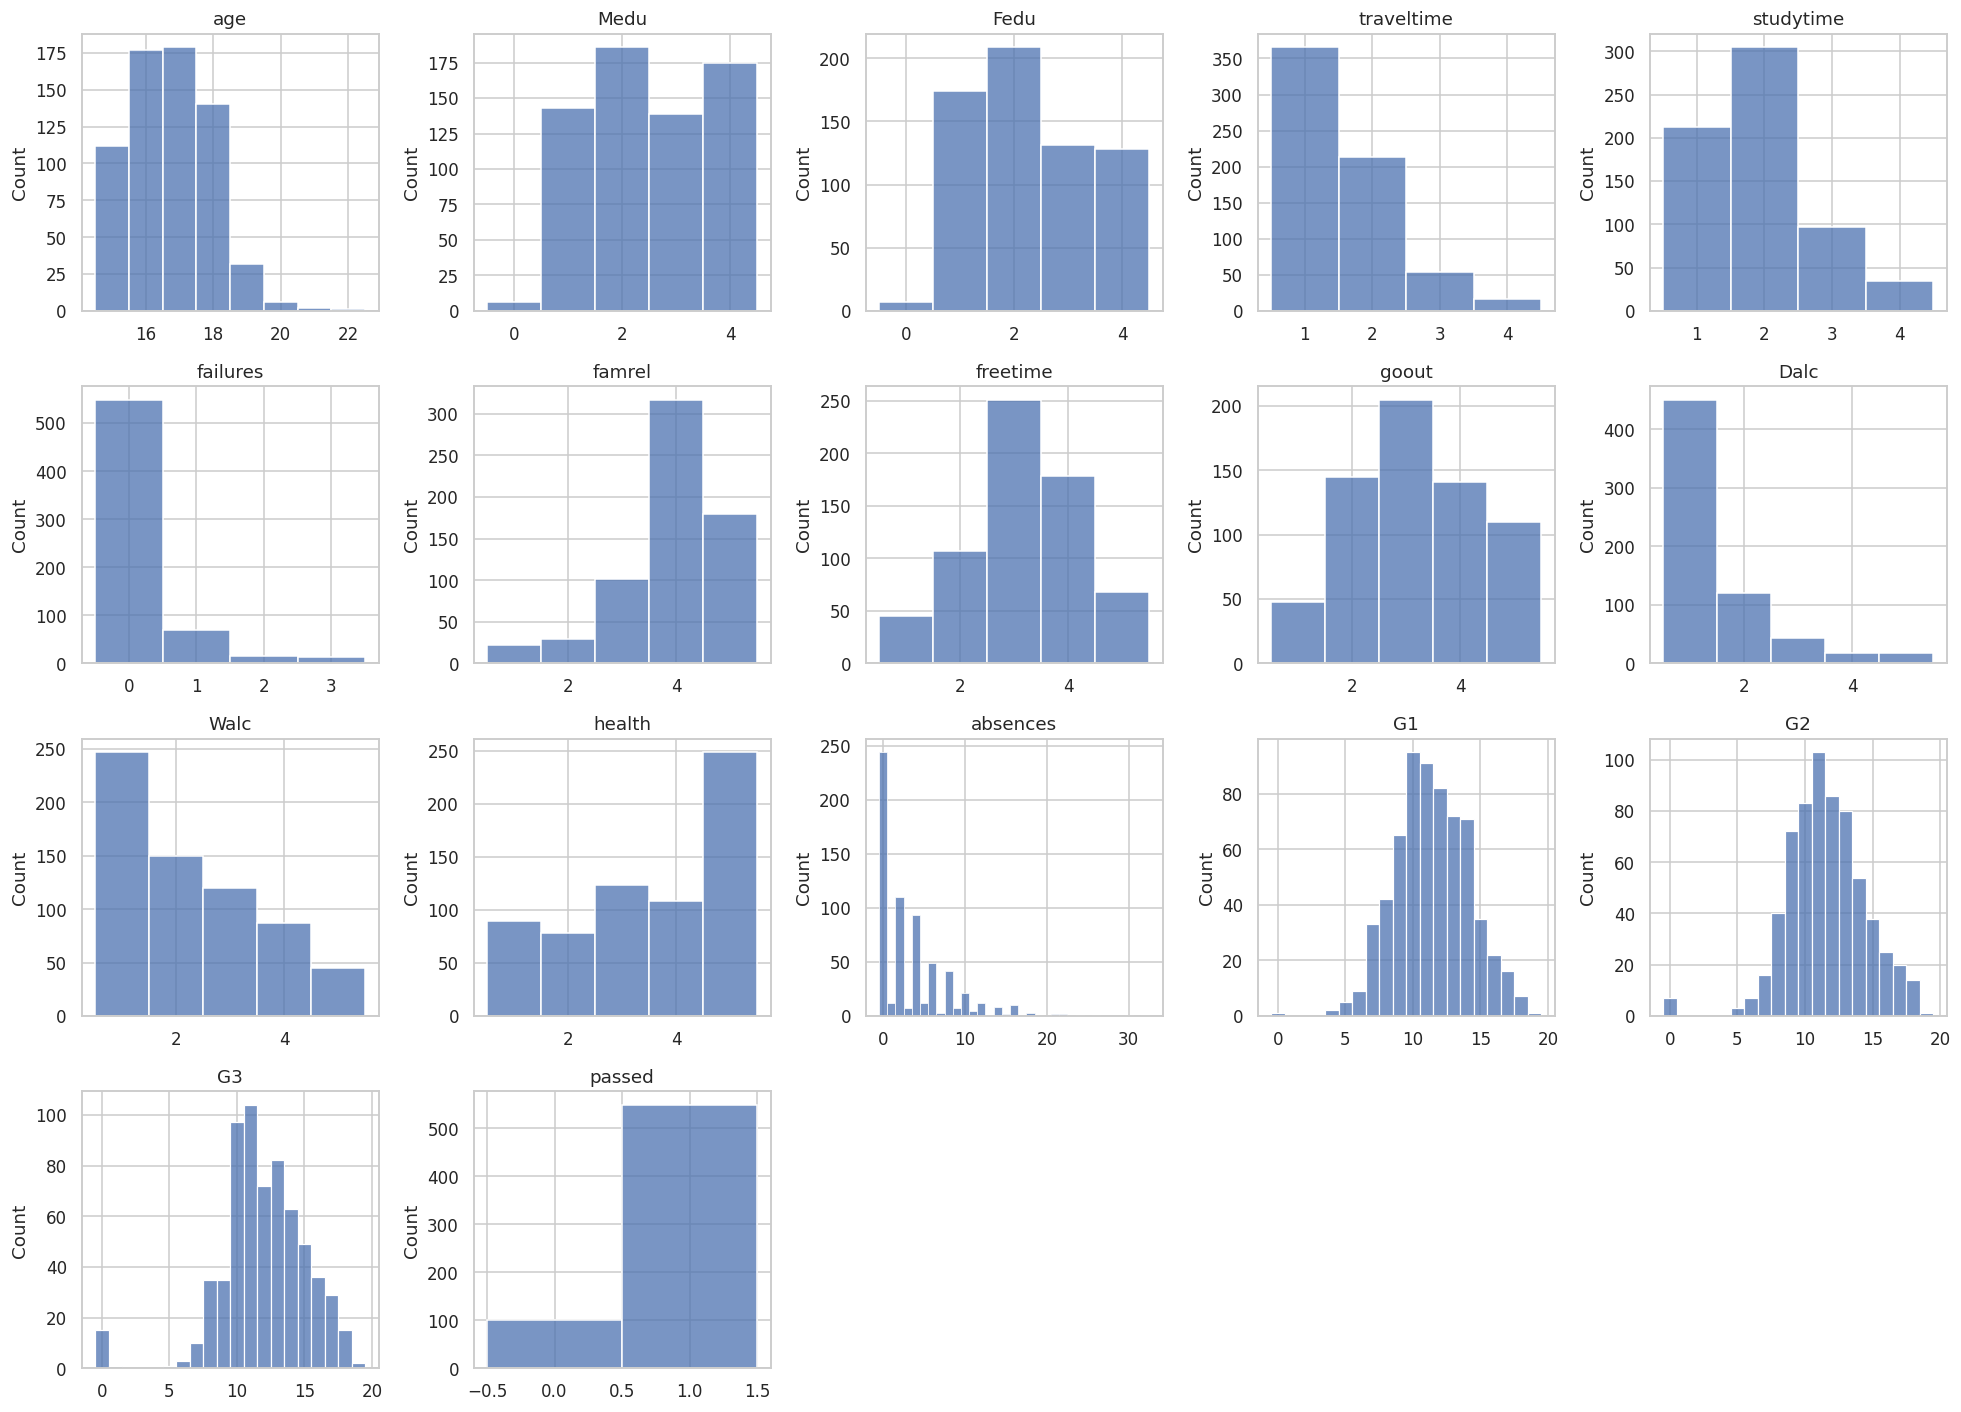

In [12]:
fig, axes = plt.subplots(4, 5, figsize=(18, 13))
for ax, col in zip(axes.ravel(), num_cols + GRADE_COLS + [TARGET]):
    sns.histplot(df[col], ax=ax, discrete=True)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols) + len(GRADE_COLS) + 1:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### 4.2. Категориальные признаки и доля сдавших

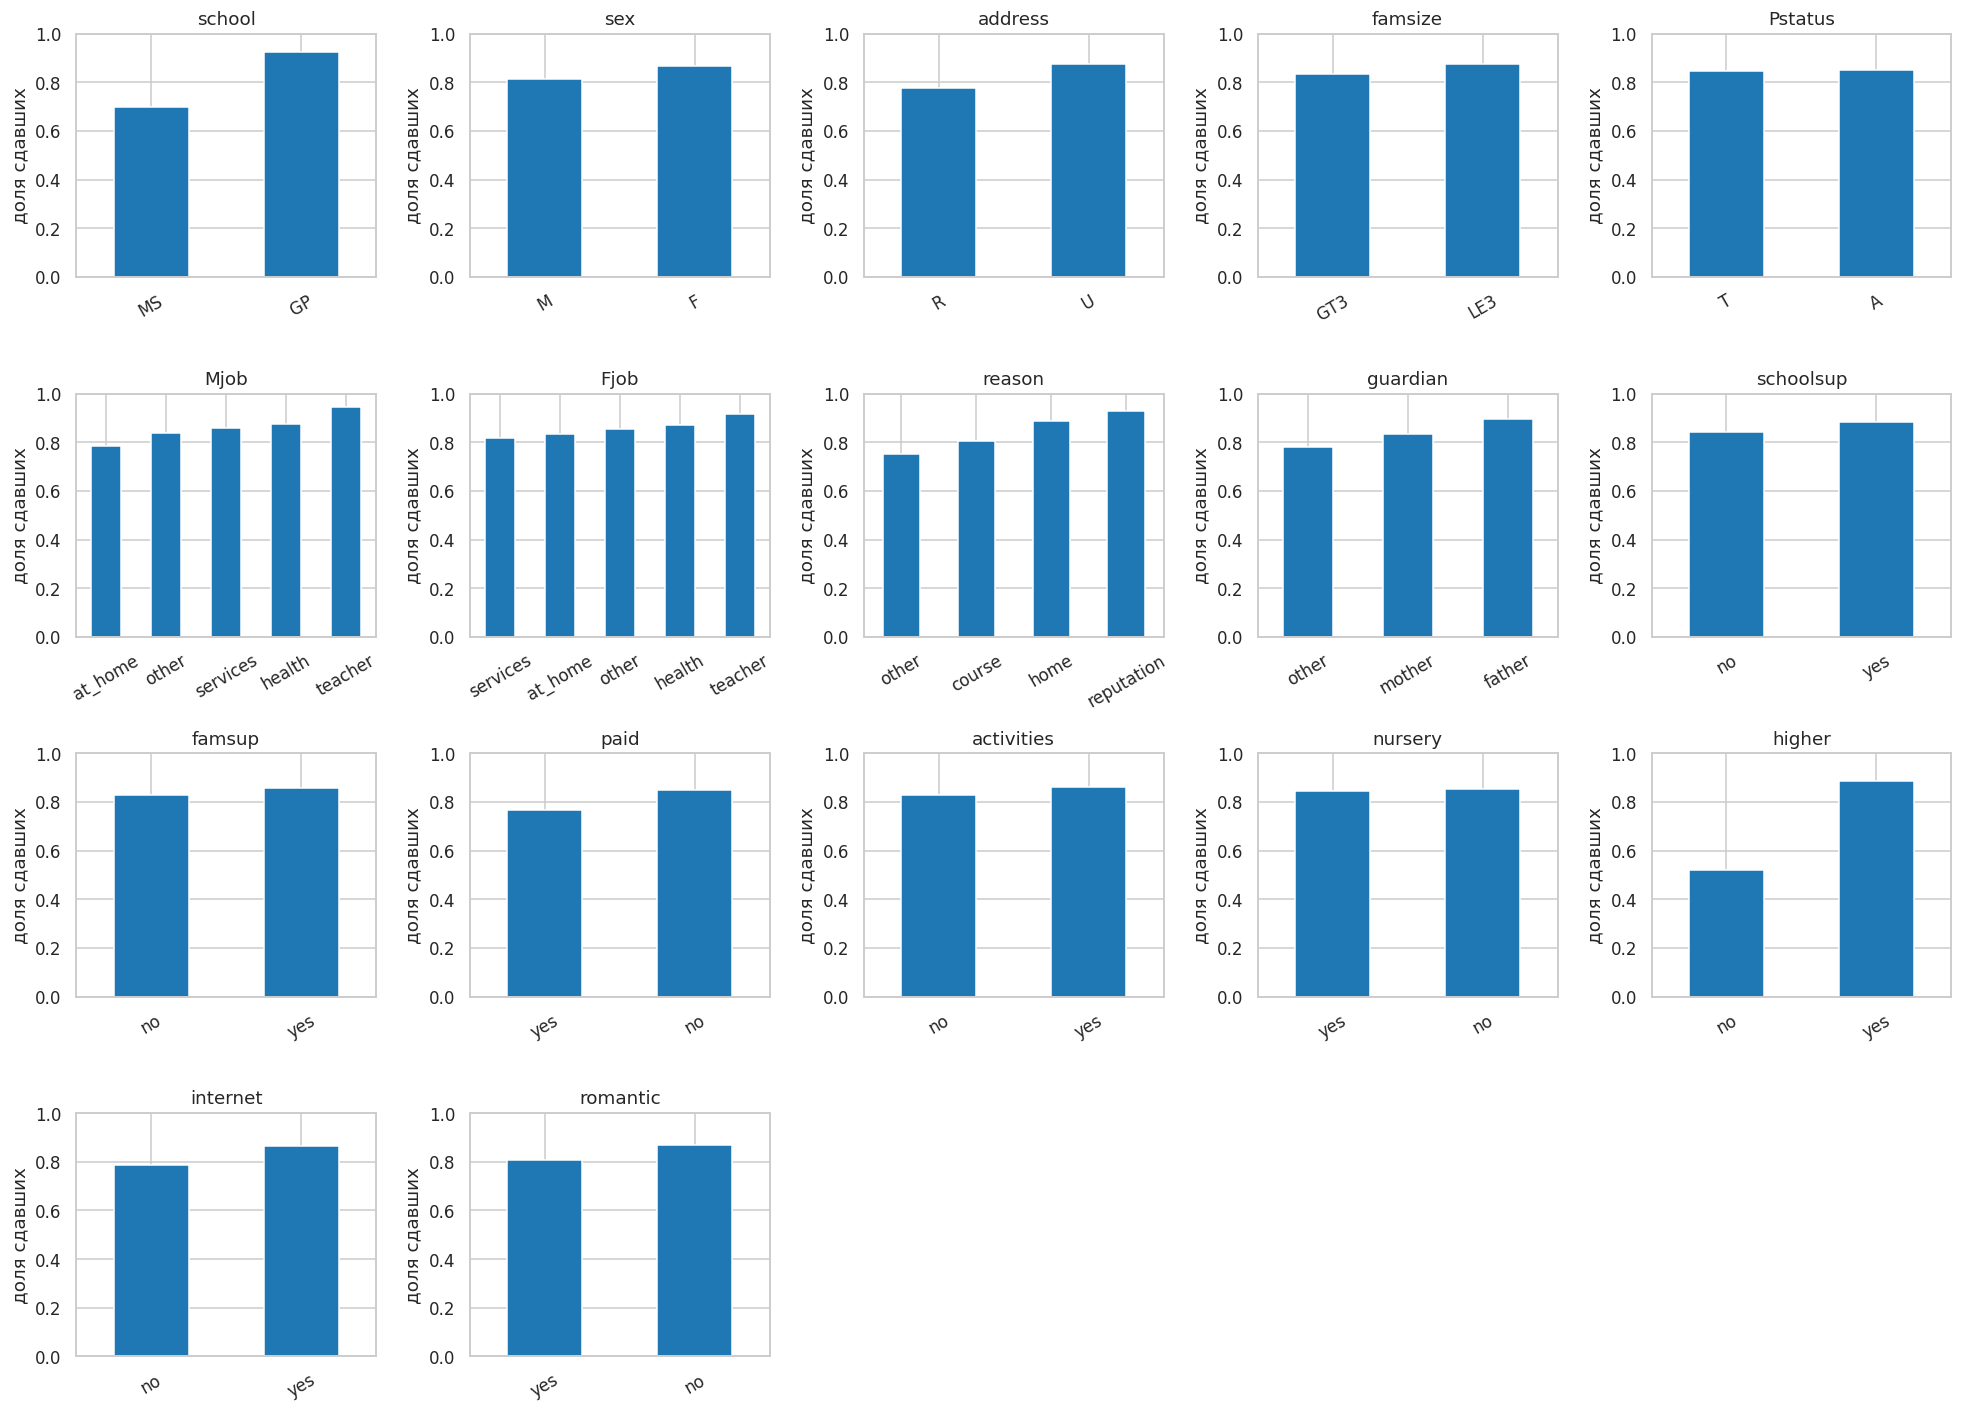

In [13]:
fig, axes = plt.subplots(4, 5, figsize=(18, 13))
for ax, col in zip(axes.ravel(), cat_cols):
    df.groupby(col)[TARGET].mean().sort_values().plot.bar(ax=ax, color="tab:blue")
    ax.set(title=col, ylabel="доля сдавших", xlabel="", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=30)
for ax in axes.ravel()[len(cat_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### 4.3. Матрица корреляции

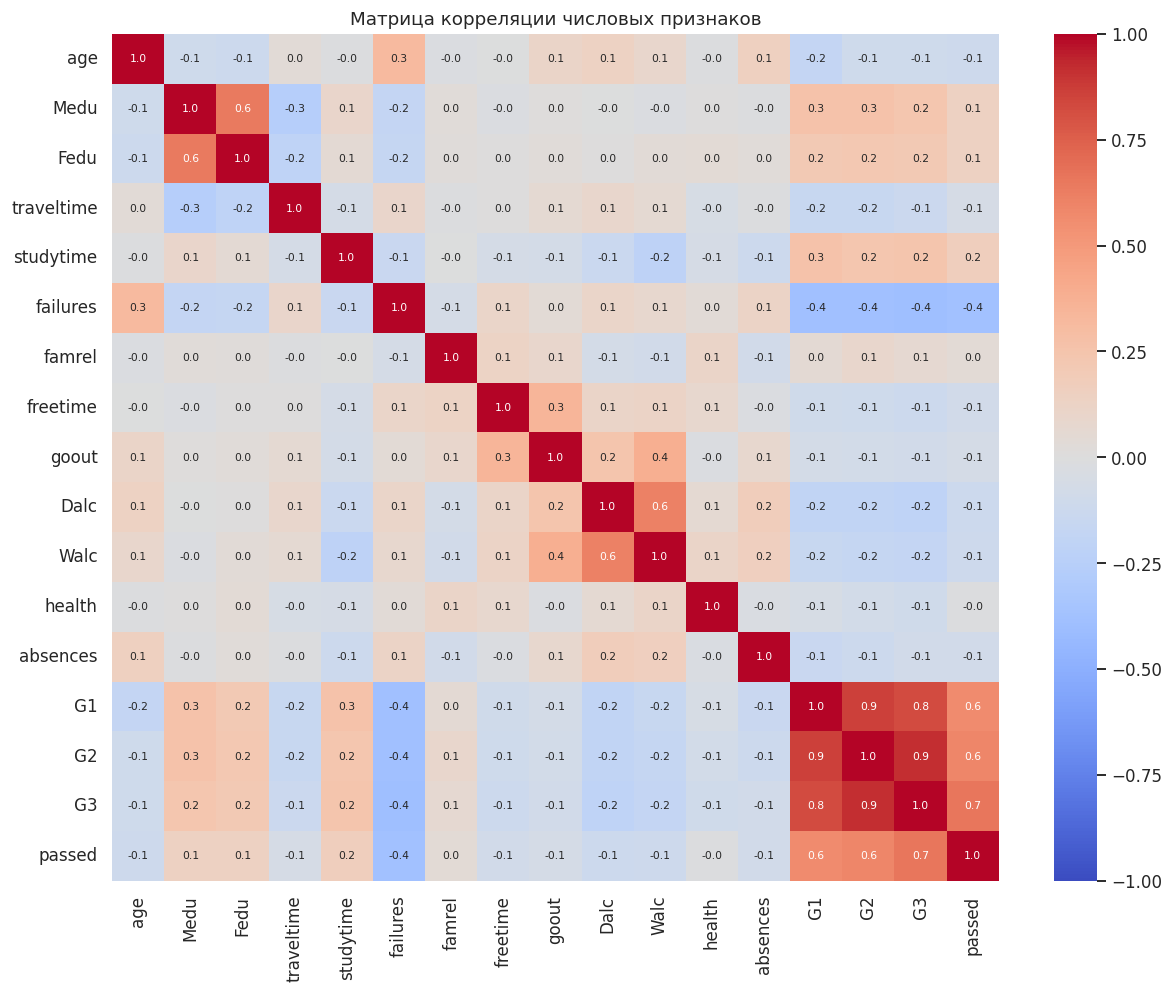

In [14]:
plt.figure(figsize=(13, 10))
sns.heatmap(df[num_cols + GRADE_COLS + [TARGET]].corr(), cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Матрица корреляции числовых признаков")
plt.show()

**Важное наблюдение — утечка данных.** Промежуточные оценки G1 и G2 коррелируют с итоговой G3 на уровне ~0.8–0.9. Если оставить их в признаках, модель «подсмотрит» почти готовый ответ, и задача потеряет практический смысл (мы хотим выявить группу риска **заранее**, до экзаменов). Поэтому G1, G2 и G3 из признаков исключаем.

Среди оставшихся признаков сильнее всего с успехом связаны `failures` (отрицательно), `higher`, `studytime`, образование родителей, а также школа.

## 5. Кодирование и разбиение
- Текстовые признаки кодируем **One-Hot**; у бинарных (`yes`/`no`, `F`/`M` …) остаётся один столбец 0/1 (`drop="if_binary"`).
- Числовые признаки передаём без масштабирования: дереву решений масштаб не важен.
- Классы несбалансированы (~85 % сдавших), поэтому разбиение **стратифицированное**, а модель обучается с `class_weight="balanced"`. Основная метрика — **F1-macro** (среднее F1 по обоим классам), чтобы модель не игнорировала редкий класс «не сдал».

In [15]:
X = df.drop(columns=GRADE_COLS + [TARGET])
y = df[TARGET]
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=SEED
)
print(f"train: {len(X_train)}, val: {len(X_val)}, test: {len(X_test)}")


def build_model(**tree_params):
    preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="most_frequent"), num_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore")),
        ]), cat_cols),
    ])
    tree = DecisionTreeClassifier(class_weight="balanced", random_state=SEED, **tree_params)
    return Pipeline([("prep", preprocessor), ("tree", tree)])

train: 389, val: 130, test: 130


## 6. Подбор гиперпараметров на валидации
Дерево без ограничений запоминает обучающую выборку (переобучается). Ограничиваем сложность:
- `max_depth` — максимальная глубина;
- `min_samples_leaf` — минимум объектов в листе;
- `criterion` — мера неоднородности узла (Джини или энтропия).

In [16]:
val_rows = []
for params in ParameterGrid(PARAM_GRID):
    model = build_model(**params).fit(X_train, y_train)
    metrics = classification_metrics(y_val, model.predict(X_val))
    train_f1 = f1_score(y_train, model.predict(X_train), average="macro")
    val_rows.append({**params, "train_f1_macro": train_f1, **metrics})

val_table = pd.DataFrame(val_rows)
val_table["depth"] = val_table["max_depth"].fillna(np.inf)
ranking = val_table.sort_values(["f1_macro", "balanced_accuracy", "depth", "min_samples_leaf"],
                                ascending=[False, False, True, False])
best_row = ranking.iloc[0]
best_params = {
    "max_depth": None if np.isinf(best_row["depth"]) else int(best_row["depth"]),
    "min_samples_leaf": int(best_row["min_samples_leaf"]),
    "criterion": best_row["criterion"],
}
print(f"Лучшие параметры: {best_params}")
ranking.drop(columns="max_depth").head(10).round(3)

Лучшие параметры: {'max_depth': 5, 'min_samples_leaf': 5, 'criterion': 'entropy'}


,criterion,min_samples_leaf,train_f1_macro,accuracy,balanced_accuracy,f1_macro,depth
45,entropy,5,0.828,0.823,0.793,0.727,5.0
53,entropy,5,0.838,0.823,0.793,0.727,8.0
57,entropy,5,0.838,0.823,0.793,0.727,10.0
61,entropy,5,0.838,0.823,0.793,0.727,inf
47,entropy,20,0.773,0.815,0.809,0.727,5.0
51,entropy,20,0.773,0.815,0.809,0.727,6.0
55,entropy,20,0.773,0.815,0.809,0.727,8.0
59,entropy,20,0.773,0.815,0.809,0.727,10.0
63,entropy,20,0.773,0.815,0.809,0.727,inf
52,entropy,1,0.981,0.854,0.730,0.725,8.0


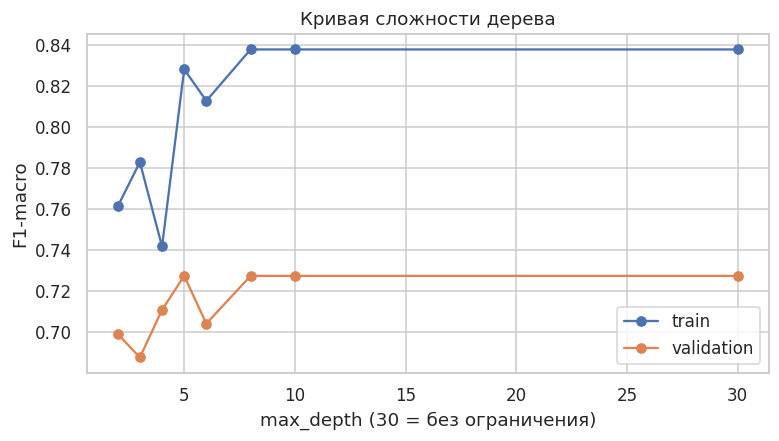

In [17]:
same_leaf = val_table["min_samples_leaf"] == best_params["min_samples_leaf"]
same_criterion = val_table["criterion"] == best_params["criterion"]
depth_curve = (val_table[same_leaf & same_criterion]
               .assign(depth=lambda t: t["depth"].replace(np.inf, 30))
               .sort_values("depth"))
ax = depth_curve.plot(x="depth", y=["train_f1_macro", "f1_macro"], marker="o", figsize=(8, 4))
ax.legend(["train", "validation"])
ax.set(xlabel="max_depth (30 = без ограничения)", ylabel="F1-macro", title="Кривая сложности дерева")
plt.show()

На кривой (при лучших `min_samples_leaf = 5` и `criterion = "entropy"`) видно, что качество на train всегда заметно выше, чем на валидации (0,83–0,84 против 0,73), — дерево частично запоминает обучающую выборку. Начиная с глубины 8, обе кривые выходят на плато: ограничение «не меньше 5 объектов в листе» не даёт дереву расти дальше, поэтому глубина 8, 10 и «без ограничения» дают одно и то же дерево. Без такого ограничения (`min_samples_leaf = 1`) F1 на train доходит до 0,98–1,0, а на валидации не растёт — это и есть **переобучение**.

Правило выбора: максимальный F1-macro на валидации; при равенстве — большая balanced accuracy, затем **более простое** дерево (меньшая глубина, больше объектов в листе). Глубина 5 даёт тот же F1, что и глубина 8 и более, поэтому выбрана она.

In [18]:
with mlflow.start_run(run_name="tree_grid_search"):
    mlflow.log_params({f"best_{k}": v for k, v in best_params.items()})
    mlflow.log_param("grid_size", len(val_table))
    mlflow.log_metrics({f"val_{k}": float(best_row[k]) for k in ["accuracy", "balanced_accuracy", "f1_macro"]})

## 7. Финальная оценка на тесте

In [19]:
final_model = build_model(**best_params).fit(X_train_full, y_train_full)
test_pred = final_model.predict(X_test)
test_metrics = classification_metrics(y_test, test_pred)
print(classification_report(y_test, test_pred, target_names=["не сдал", "сдал"]))
pd.Series(test_metrics).round(4)

              precision    recall  f1-score   support

     не сдал       0.24      0.45      0.32        20
        сдал       0.88      0.75      0.81       110

    accuracy                           0.70       130
   macro avg       0.56      0.60      0.56       130
weighted avg       0.78      0.70      0.73       130



,0
accuracy,0.7000
balanced_accuracy,0.5977
f1_macro,0.5618


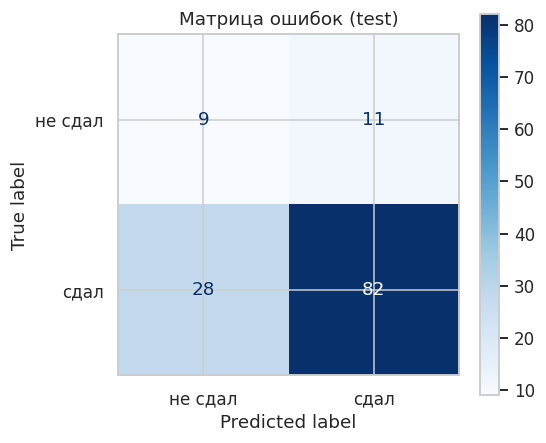

In [20]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["не сдал", "сдал"], cmap="Blues", ax=ax)
ax.set_title("Матрица ошибок (test)")
plt.show()

### Визуализация дерева и важность признаков

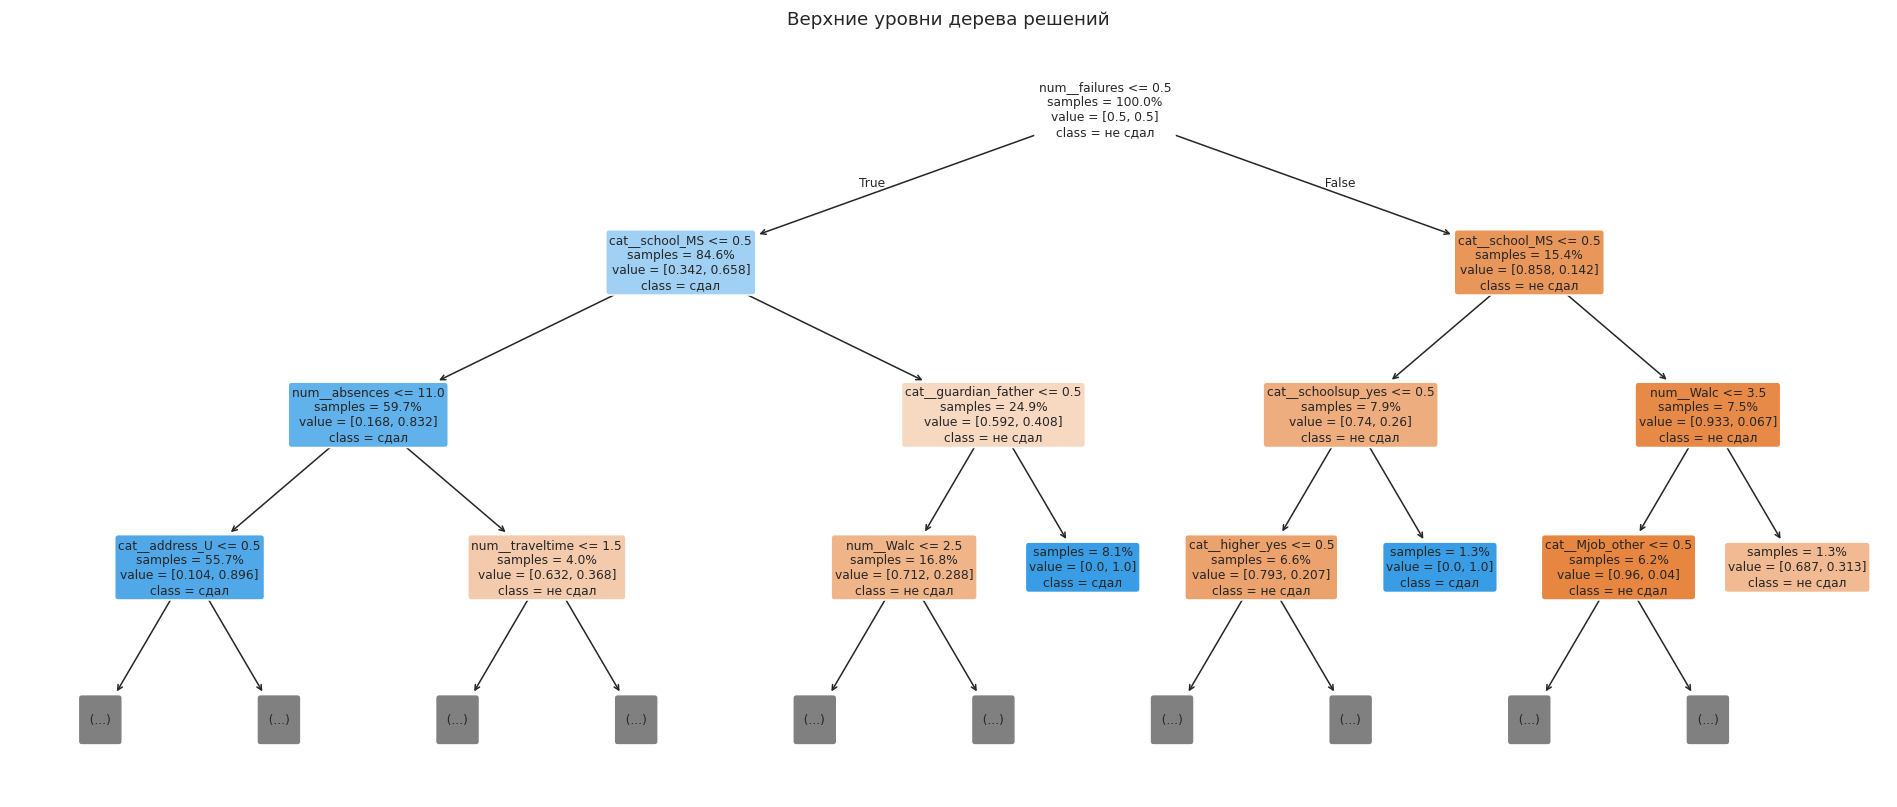

In [21]:
feature_names = final_model.named_steps["prep"].get_feature_names_out()
tree = final_model.named_steps["tree"]

plt.figure(figsize=(22, 9))
plot_tree(tree, feature_names=feature_names, class_names=["не сдал", "сдал"],
          filled=True, rounded=True, max_depth=3, fontsize=8, impurity=False, proportion=True)
plt.title("Верхние уровни дерева решений")
plt.show()

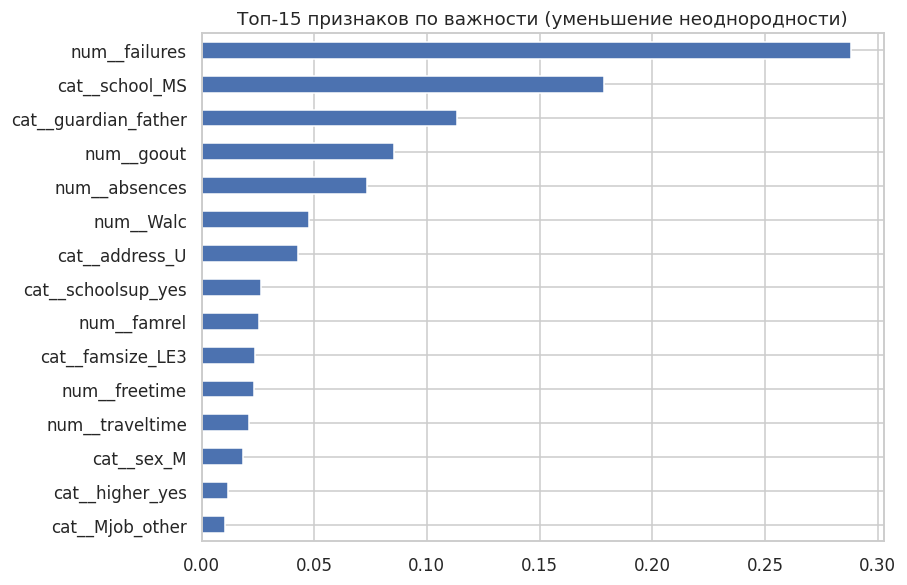

In [22]:
importances = pd.Series(tree.feature_importances_, index=feature_names).sort_values(ascending=False)
importances.head(15).sort_values().plot.barh(figsize=(8, 6))
plt.title("Топ-15 признаков по важности (уменьшение неоднородности)")
plt.show()

In [23]:
with mlflow.start_run(run_name="tree_final"):
    mlflow.log_params({**best_params, "class_weight": "balanced", "n_train": len(X_train_full)})
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_metric("tree_depth", tree.get_depth())
    mlflow.log_metric("n_leaves", tree.get_n_leaves())
    mlflow.log_figure(fig, "confusion_matrix.png")
print("Финальный запуск записан в MLflow")

Финальный запуск записан в MLflow


## 8. Выводы
- **Качество данных.** Пропусков, дубликатов и значений вне допустимых шкал в 649 записях нет; код проверки показан полностью. У 15 студентов итоговая оценка 0 (у 8 из них промежуточная G2 > 0) — это неявка на экзамен, реальный исход «не сдал», поэтому строки оставлены. 21 выброс по IQR в пропусках занятий тоже оставлен: дерево нечувствительно к выбросам.
- **Утечка данных.** Промежуточные оценки G1/G2 коррелируют с итоговой на уровне 0,83–0,92 и исключены из признаков: задача — выявить группу риска **до** экзаменов.
- **Кодирование.** 17 текстовых признаков закодированы One-Hot (у бинарных — один столбец 0/1). Классы несбалансированы (84,6 % сдавших): учтено через стратификацию, `class_weight="balanced"` и метрику F1-macro.
- **Подбор параметров.** Лучшее дерево на валидации: глубина 5, не меньше 5 объектов в листе, критерий энтропии (F1-macro 0,727).
- **Итог на тесте (130 студентов, из них только 20 не сдавших):** F1-macro **0,56**, balanced accuracy **0,60**, accuracy **0,70**. Модель нашла 9 из 20 будущих «несдавших» (recall 0,45), но ошибочно отнесла к группе риска 28 из 110 сдавших. Accuracy ниже, чем у тривиального ответа «все сдадут» (0,846), — это осознанная цена: такая модель бесполезна для поиска группы риска, а взвешивание классов заставляет дерево искать редкий класс.
- **Почему тест хуже валидации** (0,56 против 0,73). В тесте всего 20 объектов редкого класса, и ошибка на 2–3 студентах заметно меняет метрику. Кроме того, одиночное дерево — модель с **высокой дисперсией**: небольшое изменение обучающих данных меняет структуру дерева. Именно эту проблему решают ансамбли вроде случайного леса (практика 1.4). Сама задача тоже трудная: без промежуточных оценок социальные и семейные признаки объясняют успеваемость лишь частично.
- **Интерпретация** — главное преимущество дерева. Корневое правило — **были ли прошлые неудачи** (`failures`): у студентов без неудач преобладают сдавшие, у студентов с неудачами — не сдавшие. Дальше разделение идёт по школе: в MS доля несдавших выше в обеих ветвях. Типичная цепочка «сдаст»: нет прошлых неудач → школа GP → пропусков ≤ 11. По важности лидируют `failures` (0,29) и школа (0,18), далее опекун, частота встреч с друзьями (`goout`), пропуски и алкоголь в выходные (`Walc`). Важность опекуна-отца (0,11) может отчасти объясняться переобучением на малой выборке — делать по ней содержательные выводы не стоит.